# I01 — Joining PBDB occurrences with Macrostrat lithology in paleo-coordinates


**Cluster I: Paleo-biogeography.**
**Pull a taxonomic group's fossil occurrences from the Paleobiology Database (PBDB) and the contemporaneous host-rock lithology context from Macrostrat (https://macrostrat.org/), reconstruct every occurrence to one target age with `gplately`, and plot the joined record coloured by lithology. The suite's first joined-database notebook combining paleontological and stratigraphic data.**

## What this notebook produces

PBDB (paleobiodb.org) is the community fossil-occurrence database — each row a taxonomic occurrence at a known locality with a known age range. Macrostrat (macrostrat.org) is the formation-resolution stratigraphic database — each row a named geological unit with location, age range, and lithology classification. This notebook links the two spatially: an occurrence takes the lithology of the nearest Macrostrat unit of the same age, if that unit's column lies within `MAX_JOIN_KM` of the fossil locality.

This notebook does the join:

1. Pull PBDB occurrences for a taxonomic group (default: Cambrian–Ordovician brachiopods, \~520–440 Ma).
2. Query Macrostrat for every unit of the same age, with its lithology proportions, and give each occurrence the dominant lithology (carbonate / siliciclastic / other) of the nearest unit of its age within `MAX_JOIN_KM`.
3. Reconstruct each occurrence to `TARGET_TIME` with `gplately`.
4. Render a paleogeographic map at one representative target age with one dot per occurrence, coloured by lithology classification — siliciclastics in orange, carbonates in blue.

The result shows the litho-biogeography simultaneously: where in paleo-space carbonate-platform brachiopods sat versus where siliciclastic-shelf brachiopods sat at the same age. Complements I05 (PBDB paleobiogeography, without the lithology join) by adding the sedimentological dimension.

**Audience**: undergrad → postgrad.
**Difficulty**: ★★☆.

## Learning objectives

- Combine queries from two related earth-science REST APIs (PBDB + Macrostrat) into a single tidy table.
- Reconstruct a population of paleontological localities to a target age with `gplately`.
- Render a categorical paleogeographic map with explicit per-class colour coding.

## Prerequisites and runtime

- Plate model: Merdith et al. (2021) (deep-time, covers Cambrian–Ordovician).
- APIs: PBDB (https://paleobiodb.org/data1.2/) and Macrostrat (https://macrostrat.org/api/). Both free, no key, JSON responses.
- Python: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`, `requests`.
- Runtime: \~1 min. PBDB returns \~40,000 brachiopod occurrences for 520–440 Ma; both APIs are usually fast but subject to upstream rate limits. If an API cannot be reached, the notebook falls back to the cached response of an earlier live query in `data/pbdb/` or `data/macrostrat/`.


## Data availability

This notebook pulls data live from two open community APIs at runtime:

> **PBDB**: Alroy, J. et al. (Paleobiology Database community). https://paleobiodb.org/

> **Macrostrat**: Peters, S.E. et al. (2018). Macrostrat: A platform for geological data integration and deep-time Earth crust research. *Geochem. Geophys. Geosys.* 19, 1393–1409. https://doi.org/10.1029/2018GC007467

Neither API requires a key. Both are CC-BY for downstream re-use; please cite the underlying contributors via the API's standard citation field where available.

The pattern of joining PBDB and Macrostrat for paleo-spatial work was popularised by Adam Kocsis's R-side template at https://plannapus.github.io/blog/2020-11-09.html. This is the Python equivalent.

In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import os, numpy as np, pandas as pd, requests
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from pathlib import Path
from IPython.display import display, HTML
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change taxonomic group, age window, and target time

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME       = "Merdith2021"   # paleomag frame; anchor 0 = spin axis
TAXON_NAME       = "Brachiopoda"
AGE_RANGE_MA     = (440.0, 520.0)
TARGET_TIME      = 470.0          # Floian / Dapingian boundary
PBDB_BASE        = "https://paleobiodb.org/data1.2/occs/list.json"
MACROSTRAT_BASE  = "https://macrostrat.org/api/units"
MAX_JOIN_KM      = 100.0          # an occurrence takes the lithology of a unit only if its column is this close
# ============================================================================


## 1. Query PBDB (https://paleobiodb.org/) for occurrences in the age window

In [3]:
# Cell 2 — PBDB (retry, then the cached response of an earlier live query)
# The Paleobiology Database REST API sometimes times out (busy server,
# slow query). We retry up to 3 times with short backoff; if the API stays
# unreachable we load the cached response of the last successful query.
import time

params = dict(base_name=TAXON_NAME,
              max_ma=AGE_RANGE_MA[1], min_ma=AGE_RANGE_MA[0],
              show="coords", vocab="pbdb", limit="all")
PBDB_COLS = ["occurrence_no", "collection_no", "accepted_name", "accepted_rank",
             "early_interval", "late_interval", "max_ma", "min_ma", "lng", "lat"]
print(f"  GET {PBDB_BASE} ({TAXON_NAME} {AGE_RANGE_MA[0]:g}-{AGE_RANGE_MA[1]:g} Ma)")

cache_dir = Path("data/pbdb")
cache_dir.mkdir(parents=True, exist_ok=True)
cache_file = cache_dir / (
    f"pbdb_cache_{TAXON_NAME}_{int(AGE_RANGE_MA[0])}_{int(AGE_RANGE_MA[1])}.csv")

occ = None
last_err = None
for attempt, delay in enumerate([0, 2, 5]):
    if delay > 0:
        time.sleep(delay)
    try:
        print(f"  attempt {attempt + 1} ...")
        r = requests.get(PBDB_BASE, params=params, timeout=120)
        r.raise_for_status()
        occ = pd.DataFrame(r.json()["records"]).reindex(columns=PBDB_COLS)
        occ.to_csv(cache_file, index=False)
        print(f"  ✓ live fetch: {len(occ):,} occurrences (cache refreshed)")
        break
    except Exception as e:
        last_err = e
        print(f"  ✗ attempt {attempt + 1} failed: {e}")

if occ is None:
    if cache_file.exists():
        print(f"  → API unreachable; loading the cached response of an earlier query")
        occ = pd.read_csv(cache_file)
        print(f"  ✓ loaded {len(occ):,} occurrences from {cache_file}")
    else:
        raise RuntimeError(
            f"PBDB API unavailable ({last_err}) and no cached response "
            f"exists at {cache_file}. Wait and re-run.")

for _c in ("lat", "lng", "max_ma", "min_ma"):
    occ[_c] = pd.to_numeric(occ[_c], errors="coerce")
occ = occ.dropna(subset=["lat", "lng", "max_ma", "min_ma"]).reset_index(drop=True)
occ["mid_age"] = 0.5 * (occ["max_ma"] + occ["min_ma"])
print(f"  {len(occ):,} occurrences with location and age")
occ.head()

  GET https://paleobiodb.org/data1.2/occs/list.json (Brachiopoda 440-520 Ma)
  attempt 1 ...


  ✓ live fetch: 40,058 occurrences (cache refreshed)
  40,058 occurrences with location and age


,occurrence_no,collection_no,accepted_name,accepted_rank,early_interval,late_interval,max_ma,min_ma,lng,lat,mid_age
0,1182,177,Kutorgina perugata,species,Dyeran,NaN,515.3,509.7,-118.255211,37.405285,512.5
1,1183,177,Yorkia wanneri,species,Dyeran,NaN,515.3,509.7,-118.255211,37.405285,512.5
2,1232,182,Acrothele,genus,Dyeran,NaN,515.3,509.7,-73.685555,42.525555,512.5
3,1233,182,Acrotreta,genus,Dyeran,NaN,515.3,509.7,-73.685555,42.525555,512.5
4,1234,182,Bicia,genus,Dyeran,NaN,515.3,509.7,-73.685555,42.525555,512.5


## 2. Query Macrostrat (https://macrostrat.org/) for host-unit lithology classification

In [4]:
# Cell 3 — Macrostrat units with lithology (retry, then cached response) + spatial join
import time

def unit_lithology(lith):
    """Dominant lithology of a Macrostrat unit from its lithology proportions:
    'carbonate', 'siliciclastic', or 'other' (evaporite, chemical, igneous, metamorphic, ...)."""
    props = {"carbonate": 0.0, "siliciclastic": 0.0, "other": 0.0}
    for l in (lith or []):
        key = l.get("type") if l.get("type") in ("carbonate", "siliciclastic") else "other"
        props[key] += float(l.get("prop") or 0.0)
    if sum(props.values()) == 0:
        return "other", 0.0, 0.0
    return max(props, key=props.get), props["carbonate"], props["siliciclastic"]

print(f"  GET {MACROSTRAT_BASE} (age {AGE_RANGE_MA[0]:g}-{AGE_RANGE_MA[1]:g} Ma, with lithology)")
ms_cache_dir = Path("data/macrostrat")
ms_cache_dir.mkdir(parents=True, exist_ok=True)
ms_cache_file = ms_cache_dir / (
    f"units_lith_cache_{int(AGE_RANGE_MA[0])}_{int(AGE_RANGE_MA[1])}.csv")

units = None
last_err = None
for attempt, delay in enumerate([0, 2, 5]):
    if delay > 0:
        time.sleep(delay)
    try:
        print(f"  attempt {attempt + 1} ...")
        ms = requests.get(MACROSTRAT_BASE,
                          params=dict(age_top=AGE_RANGE_MA[0], age_bottom=AGE_RANGE_MA[1],
                                      response="long", format="json"),
                          timeout=120)
        ms.raise_for_status()
        rows = []
        for u in ms.json()["success"]["data"]:
            lith, carb, clas = unit_lithology(u.get("lith"))
            rows.append(dict(unit_id=u["unit_id"], col_id=u["col_id"], unit_name=u.get("unit_name"),
                             t_age=u["t_age"], b_age=u["b_age"], clat=u.get("clat"), clng=u.get("clng"),
                             lithology=lith, carbonate_prop=round(carb, 3),
                             siliciclastic_prop=round(clas, 3)))
        units = pd.DataFrame(rows)
        units.to_csv(ms_cache_file, index=False)
        print(f"  ✓ live fetch: {len(units):,} units (cache refreshed)")
        break
    except Exception as e:
        last_err = e
        print(f"  ✗ attempt {attempt + 1} failed: {e}")

if units is None:
    if ms_cache_file.exists():
        print(f"  → API unreachable; loading the cached response of an earlier query")
        units = pd.read_csv(ms_cache_file)
        print(f"  ✓ loaded {len(units):,} units from {ms_cache_file}")
    else:
        raise RuntimeError(
            f"Macrostrat API unavailable ({last_err}) and no cached response "
            f"exists at {ms_cache_file}.")
units = units.dropna(subset=["clat", "clng"]).reset_index(drop=True)
print(f"  unit lithologies: {units['lithology'].value_counts().to_dict()}")

# Spatial join. For each distinct (locality, mid-age), take the units whose age
# span contains the mid-age, find the nearest unit column (great-circle distance),
# and keep its lithology if that column is within MAX_JOIN_KM.
_ula, _ulo = np.radians(units["clat"].to_numpy()), np.radians(units["clng"].to_numpy())
_ut, _ub = units["t_age"].to_numpy(), units["b_age"].to_numpy()
_ulith = units["lithology"].to_numpy()

def join_lithology(lat, lng, age):
    ok = (_ut <= age) & (_ub >= age)
    if not ok.any():
        return "no Macrostrat unit", np.nan
    la, lo = np.radians(lat), np.radians(lng)
    cosd = (np.sin(la) * np.sin(_ula[ok])
            + np.cos(la) * np.cos(_ula[ok]) * np.cos(_ulo[ok] - lo))
    d = 6371.0 * np.arccos(np.clip(cosd, -1.0, 1.0))
    i = int(np.argmin(d))
    if d[i] > MAX_JOIN_KM:
        return "no Macrostrat unit", float(d[i])
    return _ulith[ok][i], float(d[i])

keys = occ[["lat", "lng", "mid_age"]].drop_duplicates()
joined = {k: join_lithology(*k) for k in keys.itertuples(index=False, name=None)}
occ["lithology"] = [joined[k][0] for k in occ[["lat", "lng", "mid_age"]].itertuples(index=False, name=None)]
occ["join_km"] = [joined[k][1] for k in occ[["lat", "lng", "mid_age"]].itertuples(index=False, name=None)]
print(f"  joined {len(keys):,} distinct localities × ages; occurrences by lithology:")
print(occ["lithology"].value_counts().to_string())

  GET https://macrostrat.org/api/units (age 440-520 Ma, with lithology)
  attempt 1 ...


  ✓ live fetch: 4,750 units (cache refreshed)
  unit lithologies: {'carbonate': 2546, 'siliciclastic': 1583, 'other': 621}


  joined 5,517 distinct localities × ages; occurrences by lithology:
lithology
no Macrostrat unit    24456
carbonate              8624
siliciclastic          6171
other                   807


## 3. Reconstruct each occurrence to TARGET_TIME

In [5]:
# Cell 4 — reconstruct
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
)
# Partitioner-drop guard: occurrences whose modern (lng, lat) fall
# outside any static polygon (typically over present-day ocean) get
# plate_id = 0 and are silently dropped by reconstruct(), leaving us
# with fewer returned positions than rows in `occ`. Pre-filter to keep
# lengths in sync.
pts = gplately.Points(recon, occ["lng"].values, occ["lat"].values)
plate_ids = np.atleast_1d(pts.plate_id).astype(int)
valid = plate_ids > 0
if (~valid).any():
    print(f"  dropping {int((~valid).sum())} of {len(occ)} occurrences "
          f"that fell outside any static polygon")
    occ = occ.loc[valid].reset_index(drop=True)
    pts = gplately.Points(recon, occ["lng"].values, occ["lat"].values)

rlon, rlat = pts.reconstruct(TARGET_TIME, return_array=True)
# Belt-and-braces in case reconstruct still returns fewer points
if len(rlon) < len(occ):
    print(f"  warning: reconstruct returned {len(rlon)} positions for "
          f"{len(occ)} occurrences; trimming")
    occ = occ.iloc[:len(rlon)].copy().reset_index(drop=True)

occ["paleo_lon"] = rlon
occ["paleo_lat"] = rlat


## 4. Paleogeographic map coloured by lithology


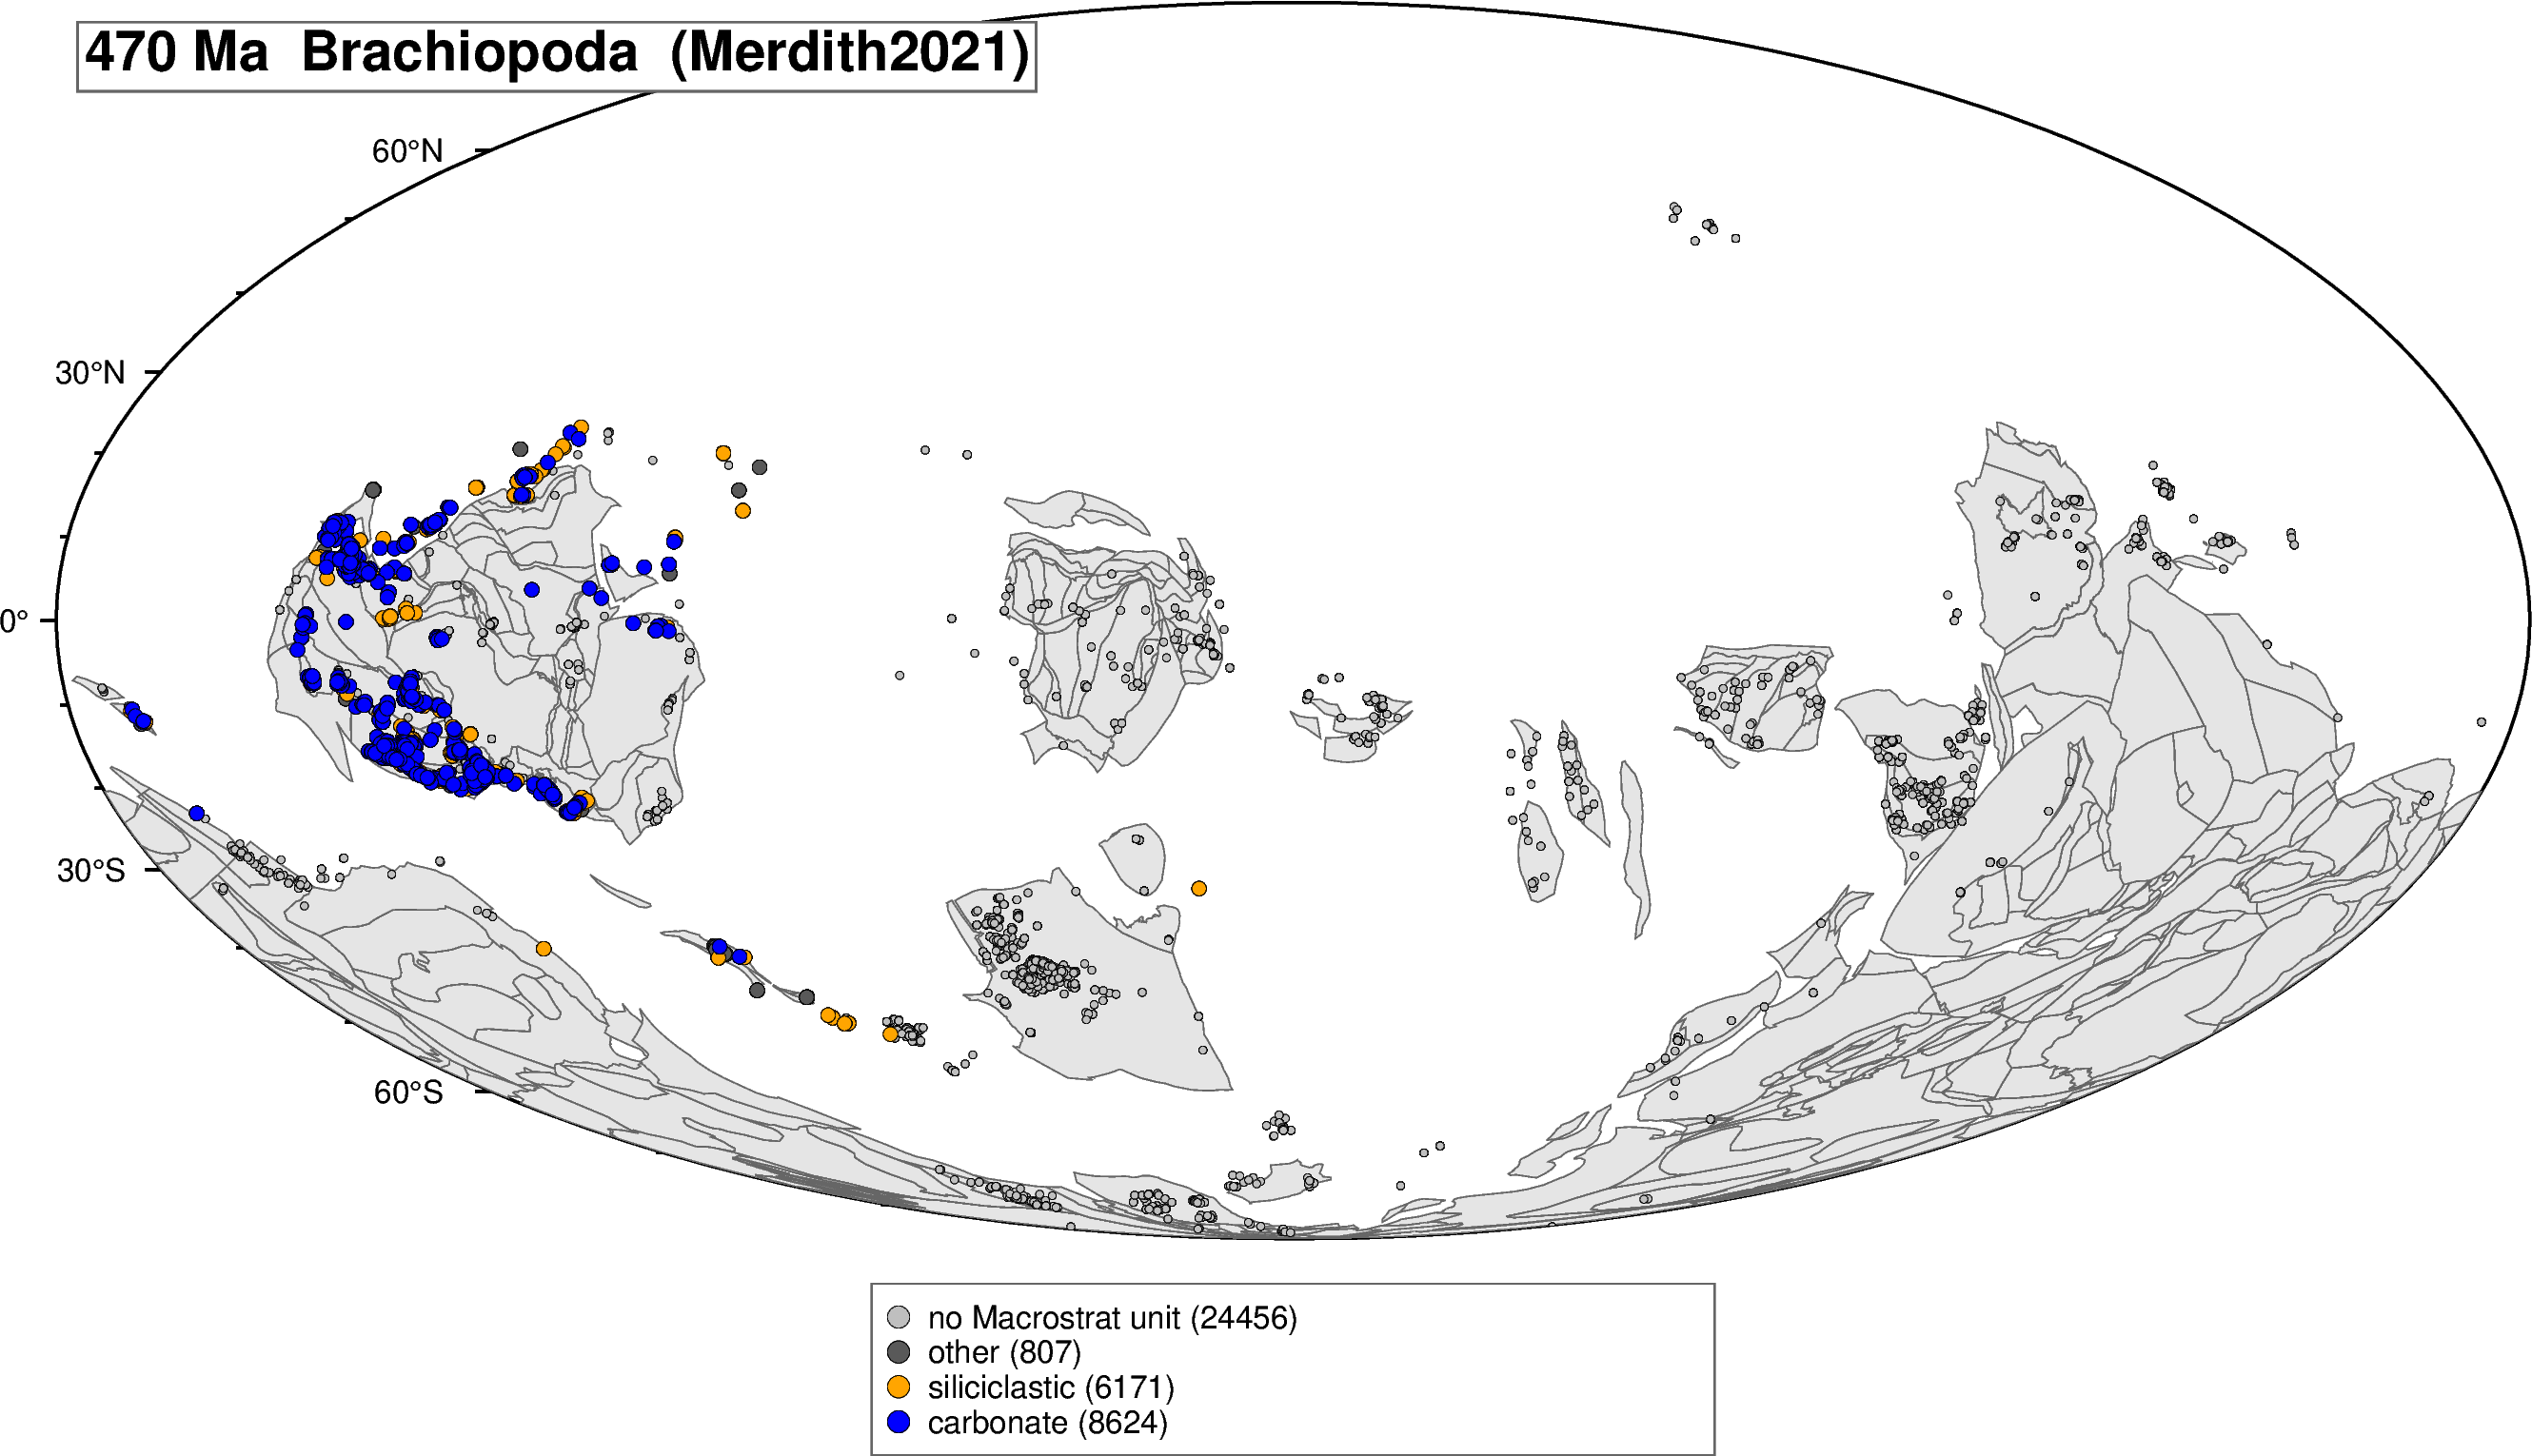

  total occurrences plotted: 40,058


In [6]:
# Cell 5 — render
LITH_COLOURS = {"no Macrostrat unit": ("gray75", "c0.07c"),   # drawn first, underneath
                "other":              ("gray35", "c0.13c"),
                "siliciclastic":      ("orange", "c0.13c"),
                "carbonate":          ("blue",   "c0.13c")}

gplot = gplately.PlotTopologies(
    plate_reconstruction=recon,
    coastlines=model.get_coastlines(),
    continents=model.get_continental_polygons(),
    COBs=model.get_COBs(),
    time=float(TARGET_TIME),

plot_engine=gplately.PygmtPlotEngine(),
)

fig = pygmt.Figure()
fig.basemap(region="d", projection="W0/22c", frame=["af"])
gplot.plot_continents(fig, fill="gray90", pen="0.3p,gray40")
for lith, (colour, symbol) in LITH_COLOURS.items():
    sub = occ[occ["lithology"] == lith]
    if len(sub) == 0: continue
    fig.plot(x=sub["paleo_lon"], y=sub["paleo_lat"],
             style=symbol, fill=colour, pen="0.15p,black",
             label=f"{lith} ({len(sub)})+S0.2c")   # no thousands comma: GMT splits labels at commas
fig.legend(position="JBC+jTC+o0/0.4c+w7.5c", box="+gwhite+p0.5p,gray40")

fig.text(text=f"{TARGET_TIME:.0f} Ma  {TAXON_NAME}  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="14p,Helvetica-Bold,black",
         fill="white", pen="0.6p,gray40")
fig.show(width=1100)
print(f"  total occurrences plotted: {len(occ):,}")


## What the figure shows

A Mollweide paleogeographic map at `TARGET_TIME` Ma with PBDB (https://paleobiodb.org/) occurrences of `TAXON_NAME` reconstructed to their paleo-positions and colour-coded by the dominant lithology of the joined Macrostrat (https://macrostrat.org/) unit: carbonate, siliciclastic, or other. Small grey dots are occurrences with no Macrostrat unit of their age within `MAX_JOIN_KM`; Macrostrat's columns cover mainly North America, so most occurrences elsewhere stay unjoined. The legend gives the count in each class; the in-frame stamp records the target age, taxon, and plate model.

What to read off:

- **Spatial concentration** in particular paleo-latitude bands or basins reveals the taxon's preferred paleo-environment at this age.
- **Lithology preference** — if the occurrence cloud is dominated by one lithology colour, the taxon was facies-specific (a carbonate-platform or shelf-sand obligate); if multiple colours coexist, the taxon was facies-tolerant.
- **Empty regions** are not necessarily evidence of absence — they may reflect the limits of the joined PBDB+Macrostrat sampling rather than the taxon's true paleo-range. The Extend-this section suggests sweeping `TARGET_TIME` to surface temporal sampling biases.

The joined dataset is the basic unit for paleo-biogeographic facies analysis: every occurrence is paired with its host rock's lithology, and the map projects the joined record into deep-time paleogeography.


## Extend this

- **Different taxonomic group.** Swap `TAXON_NAME` to `"Trilobita"`, `"Graptolithina"`, `"Conodonta"`, or anything else PBDB (https://paleobiodb.org/) knows about. The lithological-affinity pattern differs by group.
- **Sweep ages.** Loop `TARGET_TIME` from 540 to 440 Ma in 10 Myr steps and animate.
- **Per-lithology paleo-latitude distribution.** Add a side panel showing the histogram of paleo-latitudes for each lithology class — the latitudinal-belt segregation of carbonate vs siliciclastic facies should be visible.
- **Cross-reference I05 + I06.** I05 plots raw PBDB occurrences in paleo-position without the lithology join; I06 clusters PBDB occurrences into data-driven bioregions via H3 hexagonal binning. I01's joined fossil+lithology record is a natural upstream input to either downstream analysis.

## References

- Paleobiology Database (PBDB) — community-curated fossil-occurrence database, https://paleobiodb.org/ . Canonical methods reference: Alroy, J. (2010). Geographical, environmental and intrinsic biotic controls on Phanerozoic marine diversification. *Palaeontology* 53(6), 1211–1235. https://doi.org/10.1111/j.1475-4983.2010.01011.x


- Peters, S.E., Husson, J.M. & Czaplewski, J. (2018). Macrostrat: A platform for geological data integration and deep-time Earth crust research. *Geochemistry, Geophysics, Geosystems* 19, 1393–1409. https://doi.org/10.1029/2018GC007467
- Kocsis, A.T. (2020). Reconstructing PBDB occurrences in R. https://plannapus.github.io/blog/2020-11-09.html
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3–10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515

- Merdith, A.S., Williams, S.E., Collins, A.S., Tetley, M.G., Mulder, J.A., Blades, M.L., Young, A., Armistead, S.E., Cannon, J., Zahirovic, S. & Müller, R.D. (2021). Extending full-plate tectonic models into deep time: Linking the Neoproterozoic and the Phanerozoic. *Earth-Science Reviews* 214, 103477. https://doi.org/10.1016/j.earscirev.2020.103477

## See also: rgplates (the R-language equivalent)

The R-side PBDB-reconstruction workflow that inspired this notebook is now packaged into Kocsis, Raja, Williams & Dowding's [`rgplates`](https://github.com/GPlates/rgplates) — see in particular vignette 5 (*Reconstruction with data from the chronosphere*) for the production version of the workflow described in the 2020 blog post we cite as the inspiration. The Python recipe here gives the same PBDB-rotation behaviour for users whose downstream stack is `pandas` / `gplately` / `pygmt`.
